In [4]:
pip install tensorflow


Note: you may need to restart the kernel to use updated packages.


In [22]:
# loading liberaries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization
import matplotlib.pyplot as plt

In [23]:
df=pd.read_csv("diabetes_prediction_dataset.csv")
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [24]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [25]:
df.drop_duplicates(inplace=True)

In [26]:
le=LabelEncoder()
df["encode_gender"]=le.fit_transform(df["gender"])
df["encode_smoking_history"]=le.fit_transform(df["smoking_history"])

In [27]:
df.drop(columns=["smoking_history","gender"],inplace=True)

In [28]:
X=df.drop(['diabetes'],axis=1)
y=df['diabetes']

In [29]:
# splitting the data into training and testing sets
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [30]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(X_train)
x_test_scaled=scaler.transform(X_test)

In [31]:
model = Sequential()

model.add(Input(shape=(X_train.shape[1],)))

model.add(Dense(512, activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.1))

model.add(Dense(256, activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.1))

model.add(Dense(128, activation="relu"))
model.add(Dropout(0.1))

model.add(Dense(64, activation="relu"))

# Output layer for binary classification
model.add(Dense(1, activation="sigmoid"))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 180,225 (704.00 KB)

 Trainable params: 178,689 (698.00 KB)

 Non-trainable params: 1,536 (6.00 KB)

In [32]:
from tensorflow.keras.losses import BinaryCrossentropy

model.compile(
    optimizer='adam',
    loss=BinaryCrossentropy(),
    metrics=['accuracy']
)

In [33]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

In [34]:
print("X_train shape:", x_train_scaled.shape)
print("Model input shape:", model.input_shape)

X_train shape: (76916, 8)
Model input shape: (None, 8)


In [ ]:
history = model.fit(
    x_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.9565 - loss: 0.1202 - val_accuracy: 0.9624 - val_loss: 0.1009
Epoch 2/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9615 - loss: 0.1059 - val_accuracy: 0.9631 - val_loss: 0.0981
Epoch 3/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - accuracy: 0.9638 - loss: 0.1005 - val_accuracy: 0.9638 - val_loss: 0.0944
Epoch 4/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.9652 - loss: 0.0970 - val_accuracy: 0.9630 - val_loss: 0.0970
Epoch 5/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.9670 - loss: 0.0935 - val_accuracy: 0.9649 - val_loss: 0.0975
Epoch 6/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.9679 - loss: 0.0918 - val_accuracy: 0.9651 - val_loss: 0.0967
Epoch 7/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9684 - loss: 0.0909 - val_accuracy: 0.9661 - val_loss: 0.0912
Epoch 8/100
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.96

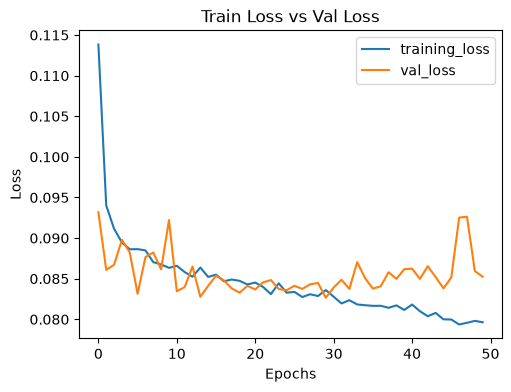

In [ ]:
plt.figure(figsize=(12, 4))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="training_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.title("Train Loss vs Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

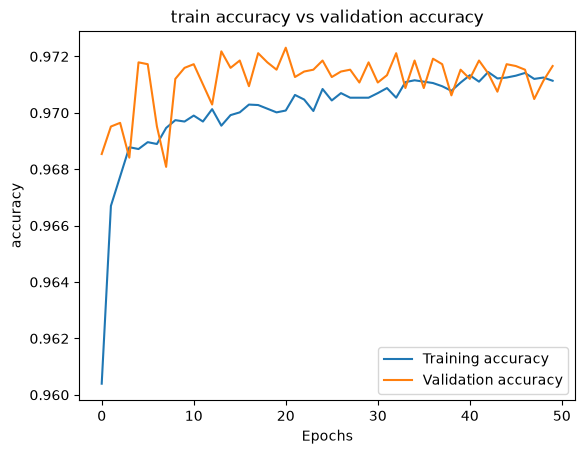

In [ ]:
# plot accuracy graph
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.title('train accuracy vs validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test_scaled, y_test, verbose=1)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

601/601 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9706 - loss: 0.0866
Test loss: 0.08656296879053116
Test accuracy: 0.9706188440322876
